KMEANS

In [175]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Data sintetis: 10 pelanggan
data = {
    'Pendapatan': [15, 55, 20, 60, 18, 70, 12, 65, 22, 58],
    'Usia':       [25, 45, 23, 50, 22, 48, 20, 52, 28, 42],
    'SkorBelanja':[12, 85, 15, 90, 10, 88,  8, 92, 18, 80]
}
df = pd.DataFrame(data)
print("Data Asli:")
print(df)

Data Asli:
   Pendapatan  Usia  SkorBelanja
0          15    25           12
1          55    45           85
2          20    23           15
3          60    50           90
4          18    22           10
5          70    48           88
6          12    20            8
7          65    52           92
8          22    28           18
9          58    42           80


In [176]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)


Silhouette Scores untuk K = 2 hingga 6:
K = 2: 0.8511
K = 3: 0.6782
K = 4: 0.4007
K = 5: 0.3331
K = 6: 0.2862


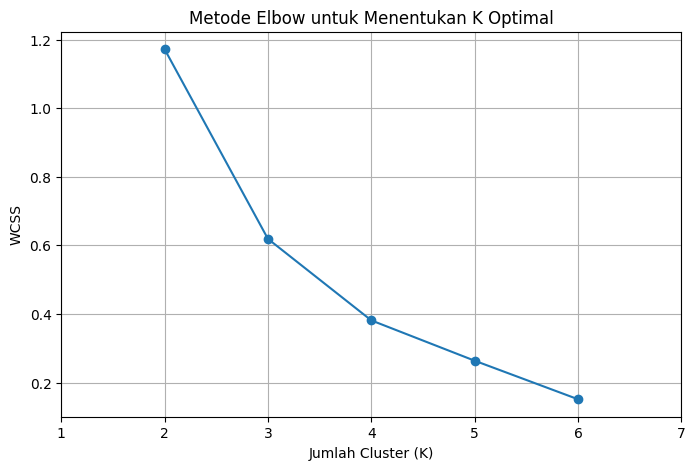

In [177]:
wcss = []
score = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    labels = kmeans.fit_predict(X_scaled)
    result = silhouette_score(X_scaled, labels)
    score.append(result)
    wcss.append(kmeans.inertia_)
    

print("\nSilhouette Scores untuk K = 2 hingga 6:")
for i, s in enumerate(score, start=2):
    print(f"K = {i}: {s:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 7), wcss, marker='o', linestyle='-')
plt.xlim(2, 6)
plt.xticks(range(1, 8))
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('WCSS')
plt.title('Metode Elbow untuk Menentukan K Optimal')
plt.grid(True)
plt.show()

In [178]:
k_optimal = 3
kmeans_final = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
cluster_labels = kmeans_final.fit_predict(X_scaled)

df['Cluster'] = cluster_labels
print("\nHasil Clustering:")
print(df)


Hasil Clustering:
   Pendapatan  Usia  SkorBelanja  Cluster
0          15    25           12        0
1          55    45           85        1
2          20    23           15        0
3          60    50           90        2
4          18    22           10        0
5          70    48           88        2
6          12    20            8        0
7          65    52           92        2
8          22    28           18        0
9          58    42           80        1


In [179]:
kategori_cluster = {0: 'Jarang', 1: 'Normal', 2: 'Sering'}
df['Kategori'] = df['Cluster'].map(kategori_cluster)
print("\nData dengan Kategori Cluster:")
print(df)


Data dengan Kategori Cluster:
   Pendapatan  Usia  SkorBelanja  Cluster Kategori
0          15    25           12        0   Jarang
1          55    45           85        1   Normal
2          20    23           15        0   Jarang
3          60    50           90        2   Sering
4          18    22           10        0   Jarang
5          70    48           88        2   Sering
6          12    20            8        0   Jarang
7          65    52           92        2   Sering
8          22    28           18        0   Jarang
9          58    42           80        1   Normal


PCA

In [180]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.4f} ({var*100:.2f}%)")

print(f"\nTotal variansi yang dipertahankan: {sum(pca.explained_variance_ratio_)*100:.2f}%")

Explained Variance Ratio:
PC1: 0.9893 (98.93%)
PC2: 0.0075 (0.75%)

Total variansi yang dipertahankan: 99.68%


In [181]:
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = cluster_labels
print("\nData dengan PCA dan Cluster:")
print(df_pca)


Data dengan PCA dan Cluster:
        PC1       PC2  Cluster
0 -1.702908  0.166548        0
1  1.385703  0.046957        1
2 -1.622268 -0.107330        0
3  1.825015  0.188147        2
4 -1.797583 -0.099147        0
5  1.956178 -0.227027        2
6 -2.075603 -0.036057        0
7  2.077462  0.154948        2
8 -1.290617  0.126799        0
9  1.244621 -0.213840        1


In [182]:
kontribusi = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=df.columns[:3]
)
print("\nKontribusi Fitur terhadap PC :")
print(kontribusi)


Kontribusi Fitur terhadap PC :
                  PC1       PC2
Pendapatan   0.576889 -0.674283
Usia         0.576558  0.735945
SkorBelanja  0.578602 -0.061058


In [183]:
kmeans_original = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_original = kmeans_original.fit_predict(X_scaled)
score_original = silhouette_score(X_scaled, labels_original)
print(f"Silhouette Score (tanpa PCA): {score_original:.4f}")

Silhouette Score (tanpa PCA): 0.6782


In [184]:
kmeans_pca = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_pca = kmeans_pca.fit_predict(X_pca)
score_pca = silhouette_score(X_pca, labels_pca)
print(f"Silhouette Score (dengan PCA):  {score_pca:.4f}")

Silhouette Score (dengan PCA):  0.6817


In [185]:
df['Cluster_pca'] = cluster_labels
print("\nHasil Clustering:")
print(df)


Hasil Clustering:
   Pendapatan  Usia  SkorBelanja  Cluster Kategori  Cluster_pca
0          15    25           12        0   Jarang            0
1          55    45           85        1   Normal            1
2          20    23           15        0   Jarang            0
3          60    50           90        2   Sering            2
4          18    22           10        0   Jarang            0
5          70    48           88        2   Sering            2
6          12    20            8        0   Jarang            0
7          65    52           92        2   Sering            2
8          22    28           18        0   Jarang            0
9          58    42           80        1   Normal            1
